# Logit Lens Evaluation Plots

This notebook generates plots for Logit Lens evaluation accuracy across multiple datasets and models.

## Setup

In [7]:
import os
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from matplotlib.gridspec import GridSpec
from safetensors.numpy import load_file

# Set project root path (adjust if necessary)
PROJECT_ROOT = os.path.expanduser("~/scratch/plm")
RESULTS_DIR = os.path.join(PROJECT_ROOT, "results")
OUTPUT_DIR = os.path.join(PROJECT_ROOT, "plots", "logitlens")

os.makedirs(OUTPUT_DIR, exist_ok=True)
print(f"Reading results from: {RESULTS_DIR}")
print(f"Saving plots to: {OUTPUT_DIR}")

# Set seaborn style (Adhering to requested standard)
sns.set_style(
    "whitegrid",
    rc={"axes.edgecolor": ".15", "xtick.bottom": True, "ytick.left": True},
)


Reading results from: /u/dssc/lbasile/scratch/plm/results
Saving plots to: /u/dssc/lbasile/scratch/plm/plots/logitlens


## Configuration

Define the datasets and models to include in the plots.

In [20]:
DATASETS = [
    ("l11p/COCOQA-restval-ICQA", ["images_qa"]),
    ("l11p/VQAv2-COCO-restval-ICQ", ["images_qa"]),
    ("lmms-lab/ScienceQA", ["images_qa"]),
    ("l11p/MME-test-captioned", ["images_qa"]),
    ("l11p/MMBench_EN-dev-captioned", ["images_qa"]),
    ("l11p/GQA-val-balanced-noyesno-captioned", ["images_qa"]),
    # ("lmms-lab/ai2d", ["images_qa"]),
    ("lmms-lab/POPE", ["images_qa"]),
    # ("lmms-lab/textvqa", ["images_qa"]),
    ("Lin-Chen/MMStar", ["images_qa"]),
    ("vikhyatk/CountBenchQA", ["images_qa"]),
]

# Multiple choice datasets for the comparison plot
MC_DATASETS = [
    # "lmms-lab/ScienceQA",
    "l11p/MME-test-captioned",
    "l11p/MMBench_EN-dev-captioned",
    # "lmms-lab/ai2d",
    "lmms-lab/POPE",
    "Lin-Chen/MMStar",
]

# (model_path, model_label)
MODELS = [
    # ("l11p/llava-v1.5-7b-pretrained-lbasile", "Pretrained"),
    ("nyu-visionx/cambrian-8b", "Finetuned"),
    ("lbasile/llava_7b", "Finetuned"),
    ("lbasile/llava_13b", "Finetuned"),
    ("lbasile/llava_13b", "Finetuned"),
    ("lmms-lab/LLaVA-OneVision-1.5-8B-Instruct", "Finetuned"),
    ("lmms-lab/LLaVA-OneVision-1.5-4B-Instruct", "Finetuned"),
    ("OpenGVLab/InternVL2-8B", "Finetuned"),
]

def load_accuracies(results_dir, model_slug, dataset_slug, subset, mode="logit_lens"):
    """
    mode: 'logit_lens' or 'linear_probe'
    """
    # Try the new filename format first
    filename = f"{model_slug}_{dataset_slug}_{subset}_{mode}.safetensors"
    path = os.path.join(results_dir, "logitlens_evaluation", filename)
    
    if os.path.exists(path):
        data = load_file(path)
        return data["accuracies"]
    
    # Fallback for older file naming convention (only for logit_lens)
    if mode == "logit_lens":
        filename_legacy = f"{model_slug}_{dataset_slug}_{subset}.safetensors"
        path_legacy = os.path.join(results_dir, "logitlens_evaluation", filename_legacy)
        if os.path.exists(path_legacy):
            return load_file(path_legacy)["accuracies"]
            
    print(f"Warning: File not found: {path}")
    return None


## Main Analysis Plots
The following cell generates the two primary plots for each model:
1. **Logit Lens Performance**: Across all configured datasets.
2. **Logit Lens vs Linear Probe**: Specifically for MC benchmarks (ScienceQA, MMBench, MME).

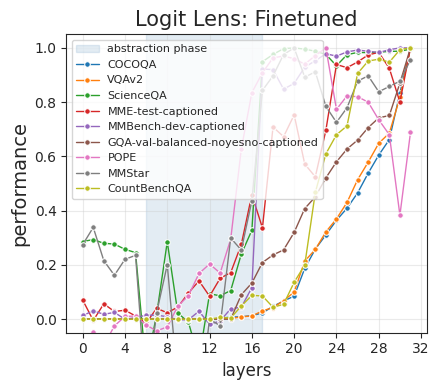

Saved Plot 1: logitlens_all_normalized_cambrian-8b.png


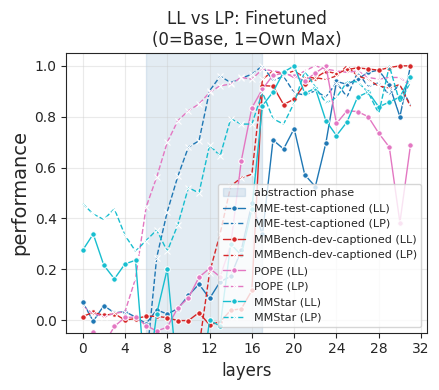

Saved Plot 2: logitlens_vs_probe_normalized_cambrian-8b.png
--------------------------------------------------


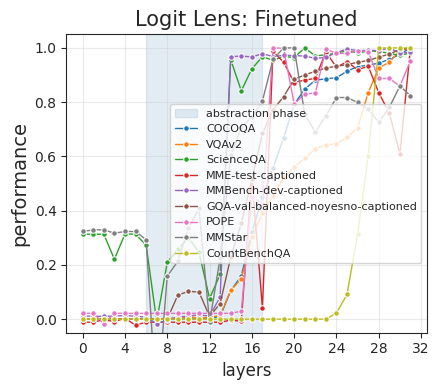

Saved Plot 1: logitlens_all_normalized_llava_7b.png


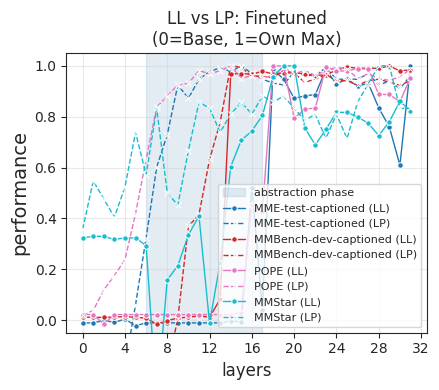

Saved Plot 2: logitlens_vs_probe_normalized_llava_7b.png
--------------------------------------------------


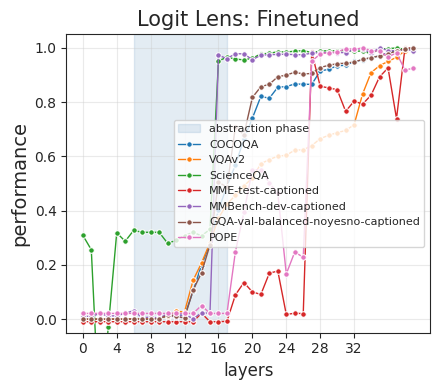

Saved Plot 1: logitlens_all_normalized_llava_13b.png


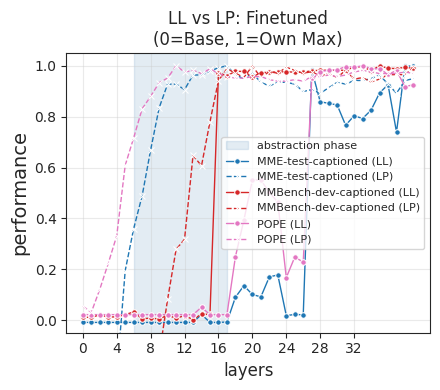

Saved Plot 2: logitlens_vs_probe_normalized_llava_13b.png
--------------------------------------------------


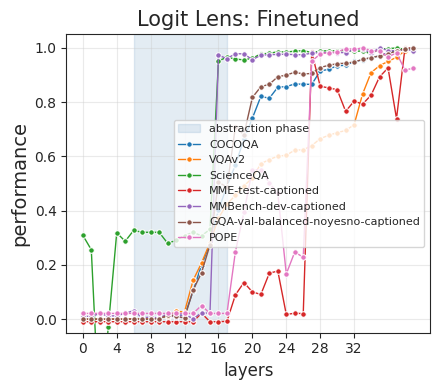

Saved Plot 1: logitlens_all_normalized_llava_13b.png


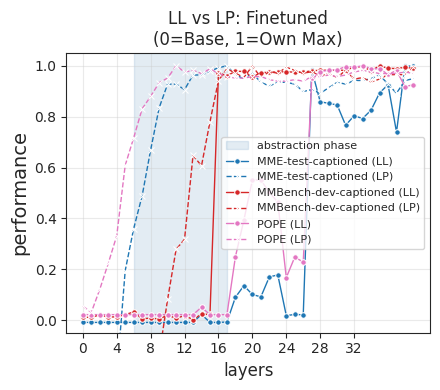

Saved Plot 2: logitlens_vs_probe_normalized_llava_13b.png
--------------------------------------------------


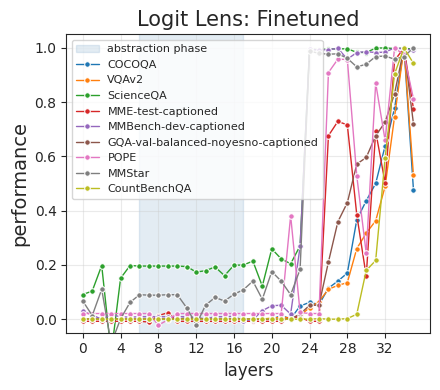

Saved Plot 1: logitlens_all_normalized_LLaVA-OneVision-1.5-8B-Instruct.png


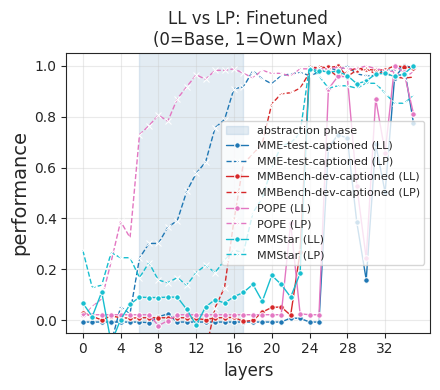

Saved Plot 2: logitlens_vs_probe_normalized_LLaVA-OneVision-1.5-8B-Instruct.png
--------------------------------------------------


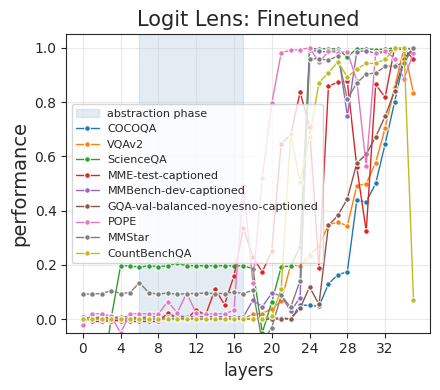

Saved Plot 1: logitlens_all_normalized_LLaVA-OneVision-1.5-4B-Instruct.png


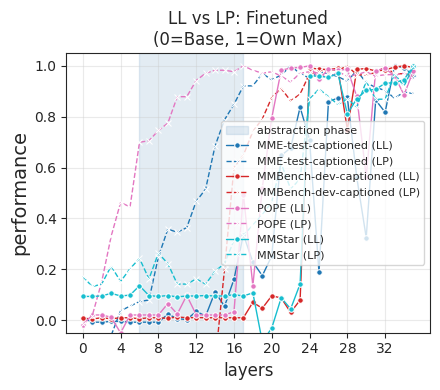

Saved Plot 2: logitlens_vs_probe_normalized_LLaVA-OneVision-1.5-4B-Instruct.png
--------------------------------------------------


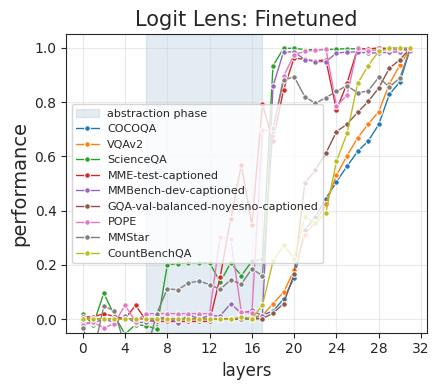

Saved Plot 1: logitlens_all_normalized_InternVL2-8B.png


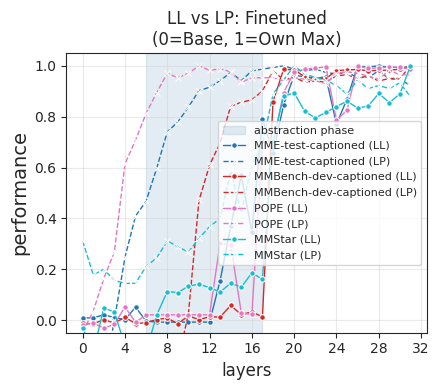

Saved Plot 2: logitlens_vs_probe_normalized_InternVL2-8B.png
--------------------------------------------------


In [14]:
# Generate plots for each model

# Baselines for normalization
BASELINES = {
    "scienceqa": 0.2,
    "mmbench_en_dev_captioned": 0.25,
    "mme_test_captioned": 0.5,
    "cocoqa_restval_icqa": 0.0,
    "vqav2_coco_restval_icq": 0.0,
    "gqa_val_balanced_noyesno_captioned": 0.0,
    "ai2d": 0.25,
    "pope": 0.5,
    "textvqa": 0.0,
    "mmstar": 0.25,
    "countbenchqa": 0.0,
}

# Flag to toggle standard deviation shading
SHOW_STD = True

def normalize_profile(arr, baseline):
    if arr is None: return None
    max_val = np.max(arr)
    if max_val <= baseline:
        denom = 1.0 # Avoid division by zero/weird plots if max <= baseline
    else:
        denom = max_val - baseline
    return (arr - baseline) / denom

for model_path, model_label in MODELS:
    model_slug = model_path.split('/')[-1]
    
    # --- Plot 1: Logit Lens Performance (All Datasets) ---
    fig_combined = plt.figure(figsize=(4.5, 4))
    gs_combined = GridSpec(1, 1)
    ax_combined = fig_combined.add_subplot(gs_combined[0])
    
    # Abstraction phase styling
    ax_combined.axvspan(
        6, 17, alpha=0.15, color="steelblue", zorder=0, label="abstraction phase"
    )

    has_data_p1 = False
    for dataset_name, subsets in DATASETS:
        dataset_slug = dataset_name.split('/')[-1].replace("-", "_").lower()
        dataset_display = dataset_name.split('/')[-1].replace("-restval-ICQA", "").replace("-COCO-restval-ICQ", "").replace("_EN", "")
        
        baseline = BASELINES.get(dataset_slug, 0.0)

        for subset in subsets:
            acc = load_accuracies(RESULTS_DIR, model_slug, dataset_slug, subset, mode="logit_lens")
            if acc is not None:
                has_data_p1 = True
                # Normalize wrt its own max
                acc_norm = normalize_profile(acc, baseline)
                
                sns.lineplot(
                    x=range(len(acc_norm)),
                    y=acc_norm,
                    label=dataset_display,
                    linewidth=1,
                    marker="o",
                    markersize=4,
                    ax=ax_combined
                )

    if has_data_p1:
        ax_combined.set_xticks(np.array(list(range(0, 33, 4))))
        ax_combined.set_ylim(-0.05, 1.05)
        ax_combined.set_ylabel("performance", fontsize=14)
        ax_combined.set_xlabel("layers", fontsize=12)
        # Legend inside to avoid narrowing the plot
        ax_combined.legend(fontsize=8, loc='best')
        ax_combined.set_title(f"Logit Lens: {model_label}", fontsize=15)
        ax_combined.grid(True, alpha=0.4)
        
        gs_combined.tight_layout(fig_combined)
        
        out_name = f"logitlens_all_normalized_{model_slug}.png"
        plt.savefig(os.path.join(OUTPUT_DIR, out_name), bbox_inches='tight', dpi=300)
        plt.show()
        print(f"Saved Plot 1: {out_name}")
    else:
        plt.close()
        print(f"No logit lens data found for {model_label}")

    # --- Plot 2: MC Benchmarks (Logit Lens vs Linear Probe) ---
    fig_combined = plt.figure(figsize=(4.5, 4))
    gs_combined = GridSpec(1, 1)
    ax_combined = fig_combined.add_subplot(gs_combined[0])
    
    ax_combined.axvspan(
        6, 17, alpha=0.15, color="steelblue", zorder=0, label="abstraction phase"
    )
    
    has_data_p2 = False
    colors = plt.cm.tab10(np.linspace(0, 1, len(MC_DATASETS)))
    
    for idx, dataset_name in enumerate(MC_DATASETS):
        # Find subsets for this dataset
        subsets = next((s for n, s in DATASETS if n == dataset_name), [])
        dataset_slug = dataset_name.split('/')[-1].replace("-", "_").lower()
        dataset_display = dataset_name.split('/')[-1].replace("_EN", "")
        color = colors[idx]
        
        # Get baseline for this dataset
        baseline = BASELINES.get(dataset_slug, 0.0)
        
        for subset in subsets:
            # Load Data
            acc_ll = load_accuracies(RESULTS_DIR, model_slug, dataset_slug, subset, mode="logit_lens")
            acc_lp = load_accuracies(RESULTS_DIR, model_slug, dataset_slug, subset, mode="linear_probe")
            
            # Plot Logit Lens
            if acc_ll is not None:
                has_data_p2 = True
                acc_ll_norm = normalize_profile(acc_ll, baseline)
                sns.lineplot(
                    x=range(len(acc_ll_norm)),
                    y=acc_ll_norm,
                    label=f"{dataset_display} (LL)",
                    color=color,
                    marker="o",
                    markersize=4,
                    linewidth=1,
                    ax=ax_combined
                )
            
            # Plot Linear Probe
            if acc_lp is not None:
                has_data_p2 = True
                acc_lp_norm = normalize_profile(acc_lp, baseline)
                sns.lineplot(
                    x=range(len(acc_lp_norm)),
                    y=acc_lp_norm,
                    label=f"{dataset_display} (LP)",
                    color=color,
                    linestyle="--",
                    linewidth=1,
                    marker="x", # Distinguish markers
                    markersize=4,
                    ax=ax_combined
                )

    if has_data_p2:
        ax_combined.set_xticks(np.array(list(range(0, 33, 4))))
        ax_combined.set_ylim(-0.05, 1.05)
        ax_combined.set_ylabel("performance", fontsize=14)
        ax_combined.set_xlabel("layers", fontsize=12)
        # Legend inside to avoid narrowing the plot
        ax_combined.legend(fontsize=8, loc='best')
        ax_combined.set_title(f"LL vs LP: {model_label}\n(0=Base, 1=Own Max)", fontsize=12)
        ax_combined.grid(True, alpha=0.4)
        
        gs_combined.tight_layout(fig_combined)
        
        out_name = f"logitlens_vs_probe_normalized_{model_slug}.png"
        plt.savefig(os.path.join(OUTPUT_DIR, out_name), bbox_inches='tight', dpi=300)
        plt.show()
        print(f"Saved Plot 2: {out_name}")
    else:
        plt.close()
        print(f"No MC benchmark data found for {model_label}")
        
    print("-" * 50)


Processing model: Finetuned
None
None
[0.3775 0.3725 0.4025 0.405  0.385  0.4    0.4    0.4175 0.4025 0.4325
 0.4325 0.475  0.61   0.6825 0.6775 0.6775 0.6725 0.705  0.695  0.71
 0.71   0.6975 0.715  0.7075 0.7025 0.69   0.6925 0.69   0.7    0.69
 0.6925 0.665 ]
[0.4725 0.4175 0.4    0.395  0.3975 0.42   0.4475 0.575  0.63   0.6725
 0.7075 0.715  0.775  0.7925 0.785  0.79   0.795  0.805  0.7875 0.7925
 0.7725 0.77   0.775  0.7675 0.785  0.7675 0.7975 0.78   0.785  0.77
 0.7825 0.7575]
[0.2175 0.215  0.1925 0.1775 0.1725 0.1625 0.165  0.17   0.1575 0.1675
 0.2075 0.21   0.32   0.3775 0.4475 0.46   0.465  0.605  0.6175 0.6125
 0.6175 0.6075 0.6075 0.605  0.61   0.625  0.61   0.605  0.595  0.5925
 0.5975 0.565 ]
None
[0.52   0.51   0.505  0.51   0.5125 0.5625 0.67   0.715  0.7675 0.8
 0.815  0.825  0.8425 0.8525 0.855  0.865  0.8625 0.8775 0.875  0.8725
 0.865  0.875  0.8825 0.8775 0.875  0.8725 0.875  0.865  0.8625 0.865
 0.865  0.8525]
[0.32333333 0.31666667 0.31333333 0.32       0.3033

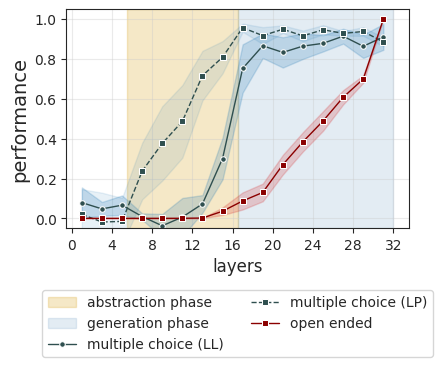

Saved Aggregated Plot: aggregated_normalized_cambrian-8b.pdf
--------------------------------------------------
Processing model: Finetuned
None
None
[0.3925 0.3575 0.3725 0.3675 0.3825 0.3925 0.3875 0.38   0.42   0.425
 0.4875 0.545  0.615  0.625  0.6975 0.695  0.6975 0.7    0.685  0.675
 0.6925 0.6725 0.6875 0.6825 0.6775 0.685  0.6825 0.67   0.6675 0.65
 0.66   0.665 ]
[0.485  0.44   0.45   0.4325 0.44   0.52   0.6075 0.7    0.7425 0.8075
 0.79   0.815  0.825  0.83   0.825  0.8325 0.8225 0.815  0.81   0.8075
 0.825  0.82   0.82   0.83   0.815  0.815  0.815  0.8225 0.8075 0.8125
 0.8025 0.82  ]
[0.21   0.195  0.18   0.1675 0.14   0.14   0.155  0.15   0.17   0.2525
 0.4075 0.4275 0.52   0.5825 0.6775 0.675  0.66   0.66   0.6575 0.67
 0.665  0.65   0.655  0.6625 0.6525 0.6525 0.645  0.6525 0.655  0.65
 0.645  0.6525]
None
[0.5075 0.515  0.5475 0.57   0.595  0.6675 0.7525 0.835  0.8525 0.87
 0.8725 0.8925 0.8875 0.8925 0.9    0.88   0.885  0.88   0.885  0.8975
 0.8875 0.8925 0.885  0.89

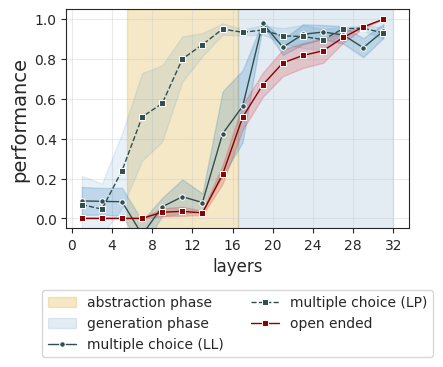

Saved Aggregated Plot: aggregated_normalized_llava_7b.pdf
--------------------------------------------------
Processing model: Finetuned
None
None
[0.3875 0.3675 0.3675 0.385  0.3925 0.385  0.3775 0.3625 0.42   0.4175
 0.48   0.5125 0.555  0.635  0.6425 0.6625 0.6975 0.7075 0.7075 0.705
 0.695  0.7025 0.715  0.71   0.7025 0.7125 0.695  0.695  0.6875 0.6975
 0.6975 0.6975 0.6975 0.6975 0.6875 0.69   0.7075 0.705  0.695  0.705 ]
[0.4825 0.4175 0.415  0.41   0.4225 0.5675 0.625  0.67   0.7325 0.79
 0.8225 0.8225 0.815  0.835  0.835  0.84   0.845  0.8475 0.835  0.83
 0.8375 0.825  0.82   0.825  0.825  0.8225 0.8125 0.815  0.81   0.8175
 0.825  0.8225 0.8275 0.8275 0.83   0.835  0.8225 0.81   0.8275 0.83  ]
[0.205  0.1775 0.1475 0.1325 0.1325 0.1575 0.1175 0.1225 0.1475 0.19
 0.285  0.37   0.3875 0.53   0.5125 0.5875 0.6575 0.6775 0.67   0.6625
 0.6825 0.6625 0.6725 0.67   0.68   0.675  0.67   0.6725 0.665  0.67
 0.6625 0.675  0.66   0.6625 0.655  0.66   0.6675 0.6675 0.6675 0.68  ]
None
[0

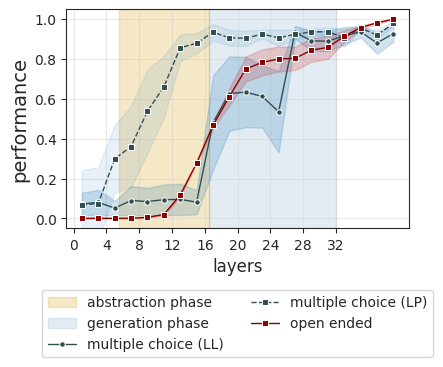

Saved Aggregated Plot: aggregated_normalized_llava_13b.pdf
--------------------------------------------------
Processing model: Finetuned
None
None
[0.3875 0.3675 0.3675 0.385  0.3925 0.385  0.3775 0.3625 0.42   0.4175
 0.48   0.5125 0.555  0.635  0.6425 0.6625 0.6975 0.7075 0.7075 0.705
 0.695  0.7025 0.715  0.71   0.7025 0.7125 0.695  0.695  0.6875 0.6975
 0.6975 0.6975 0.6975 0.6975 0.6875 0.69   0.7075 0.705  0.695  0.705 ]
[0.4825 0.4175 0.415  0.41   0.4225 0.5675 0.625  0.67   0.7325 0.79
 0.8225 0.8225 0.815  0.835  0.835  0.84   0.845  0.8475 0.835  0.83
 0.8375 0.825  0.82   0.825  0.825  0.8225 0.8125 0.815  0.81   0.8175
 0.825  0.8225 0.8275 0.8275 0.83   0.835  0.8225 0.81   0.8275 0.83  ]
[0.205  0.1775 0.1475 0.1325 0.1325 0.1575 0.1175 0.1225 0.1475 0.19
 0.285  0.37   0.3875 0.53   0.5125 0.5875 0.6575 0.6775 0.67   0.6625
 0.6825 0.6625 0.6725 0.67   0.68   0.675  0.67   0.6725 0.665  0.67
 0.6625 0.675  0.66   0.6625 0.655  0.66   0.6675 0.6675 0.6675 0.68  ]
None
[

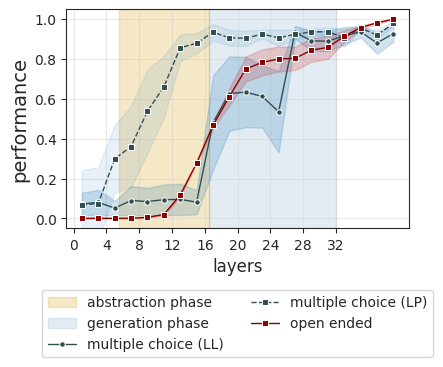

Saved Aggregated Plot: aggregated_normalized_llava_13b.pdf
--------------------------------------------------
Processing model: Finetuned
None
None
[0.355  0.395  0.39   0.365  0.355  0.365  0.3675 0.38   0.4025 0.3925
 0.415  0.4025 0.4175 0.42   0.445  0.485  0.6175 0.7225 0.7875 0.8675
 0.9175 0.95   0.95   0.96   0.98   0.9875 0.9825 0.985  0.9825 0.985
 0.9825 0.985  0.985  0.985  0.985  0.985 ]
[0.4325 0.415  0.4125 0.465  0.52   0.51   0.595  0.6175 0.6175 0.6425
 0.6525 0.6975 0.725  0.7425 0.795  0.8075 0.855  0.8575 0.8825 0.87
 0.8625 0.875  0.8775 0.88   0.875  0.88   0.8875 0.8825 0.89   0.8775
 0.875  0.875  0.885  0.8825 0.89   0.8875]
[0.18   0.1525 0.1425 0.1225 0.13   0.1425 0.14   0.1525 0.15   0.165
 0.135  0.1575 0.16   0.18   0.2775 0.3225 0.4725 0.6    0.62   0.645
 0.7325 0.755  0.7575 0.7675 0.8025 0.8175 0.81   0.7925 0.805  0.8125
 0.81   0.8    0.8025 0.7925 0.79   0.7925]
None
[0.505  0.5225 0.535  0.5975 0.665  0.6375 0.81   0.825  0.8425 0.8325
 0.87   0.

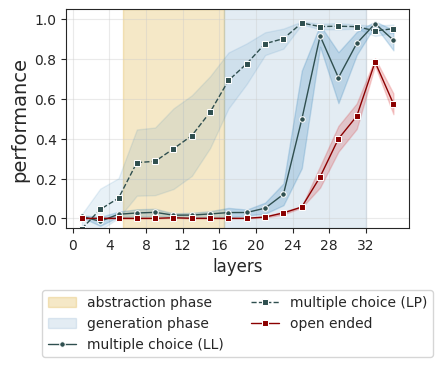

Saved Aggregated Plot: aggregated_normalized_LLaVA-OneVision-1.5-8B-Instruct.pdf
--------------------------------------------------
Processing model: Finetuned
None
None
[0.37   0.3875 0.3975 0.415  0.3925 0.38   0.405  0.39   0.365  0.3875
 0.3725 0.3875 0.3575 0.38   0.3825 0.49   0.61   0.6925 0.7725 0.8475
 0.9225 0.9325 0.945  0.945  0.975  0.975  0.975  0.975  0.975  0.97
 0.97   0.975  0.9725 0.9725 0.9775 0.975 ]
[0.4375 0.4375 0.4375 0.475  0.515  0.5225 0.53   0.5325 0.6025 0.6475
 0.6425 0.65   0.6925 0.7125 0.7825 0.825  0.85   0.88   0.88   0.9
 0.89   0.8975 0.9125 0.9    0.8925 0.9025 0.9    0.895  0.8875 0.905
 0.885  0.8775 0.8725 0.86   0.87   0.8675]
[0.1875 0.1825 0.1675 0.1275 0.125  0.1325 0.105  0.115  0.09   0.1025
 0.1    0.1125 0.1    0.115  0.155  0.3625 0.5875 0.615  0.6675 0.695
 0.7425 0.7625 0.735  0.75   0.795  0.8    0.805  0.8025 0.8125 0.7925
 0.7925 0.7975 0.81   0.795  0.795  0.79  ]
None
[0.4925 0.5075 0.565  0.6425 0.7    0.6925 0.8025 0.805  0.82

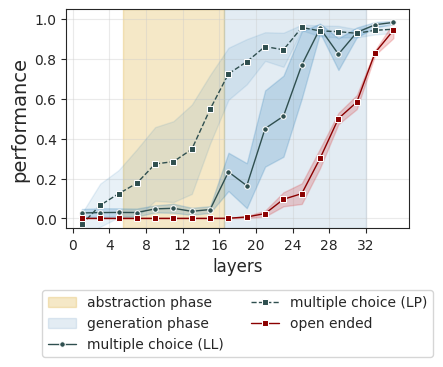

Saved Aggregated Plot: aggregated_normalized_LLaVA-OneVision-1.5-4B-Instruct.pdf
--------------------------------------------------
Processing model: Finetuned
None
None
[0.3575 0.3475 0.3925 0.395  0.42   0.4    0.3825 0.375  0.42   0.435
 0.49   0.6625 0.6975 0.795  0.8875 0.905  0.9325 0.945  0.9625 0.9675
 0.9675 0.965  0.9625 0.9625 0.9625 0.965  0.965  0.965  0.965  0.9625
 0.965  0.965 ]
[0.445  0.415  0.4125 0.5    0.595  0.6575 0.68   0.73   0.785  0.8
 0.8225 0.8475 0.8525 0.8625 0.875  0.8625 0.8775 0.88   0.8825 0.885
 0.88   0.8775 0.88   0.875  0.8725 0.875  0.8675 0.8675 0.8775 0.865
 0.865  0.855 ]
[0.175  0.17   0.1875 0.17   0.14   0.1375 0.12   0.1125 0.1275 0.1675
 0.2625 0.4875 0.5575 0.6025 0.675  0.6825 0.6875 0.705  0.745  0.7275
 0.7325 0.7225 0.725  0.7225 0.735  0.7375 0.73   0.735  0.725  0.73
 0.73   0.755 ]
None
[0.48   0.515  0.57   0.615  0.7625 0.8025 0.8475 0.8825 0.915  0.9075
 0.915  0.9275 0.92   0.9225 0.9175 0.9    0.9075 0.9075 0.9075 0.9025
 0.9

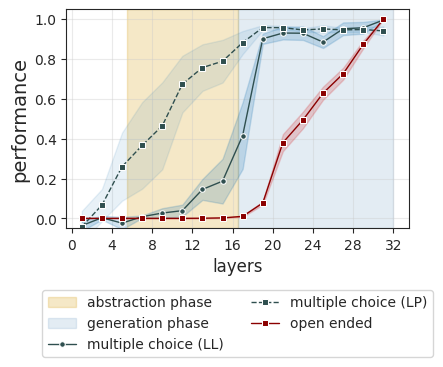

Saved Aggregated Plot: aggregated_normalized_InternVL2-8B.pdf
--------------------------------------------------


In [21]:
# --- Plot 3: Aggregated MME/MMBench vs QA ---

# Define groups based on the DATASETS list
GROUP_MC = ["l11p/MME-test-captioned", "l11p/MMBench_EN-dev-captioned", "lmms-lab/POPE", "Lin-Chen/MMStar"]
# GROUP_MC = ["l11p/MMBench_EN-dev-captioned", "lmms-lab/POPE"]
GROUP_QA = ["l11p/GQA-val-balanced-noyesno-captioned", "l11p/COCOQA-restval-ICQA", "l11p/VQAv2-COCO-restval-ICQ"]

# Helper to average arrays of potentially different lengths (clips to min len)
def average_arrays(arrays):
    if not arrays:
        return None, None
    min_len = min(len(arr) for arr in arrays)
    # Clip all to min_len
    clipped = [arr[:min_len] for arr in arrays]
    return np.mean(clipped, axis=0), np.std(clipped, axis=0)

for model_path, model_label in MODELS:
    model_slug = model_path.split('/')[-1]
    
    # Containers for normalized profiles
    mc_ll_profiles = [] # Logit Lens for MME & MMB
    mc_lp_profiles = [] # Linear Probe for MME & MMB
    qa_ll_profiles = [] # Logit Lens for VQAv2 & COCOQA

    print(f"Processing model: {model_label}")

    for dataset_name, subsets in DATASETS:
        dataset_slug = dataset_name.split('/')[-1].replace("-", "_").lower()
        baseline = BASELINES.get(dataset_slug, 0.0)
        
        # We assume 1 subset for simplicity or take the first valid one
        for subset in subsets:
            # Load Raw
            raw_ll = load_accuracies(RESULTS_DIR, model_slug, dataset_slug, subset, mode="logit_lens")
            raw_lp = load_accuracies(RESULTS_DIR, model_slug, dataset_slug, subset, mode="linear_probe")
            print(raw_lp)
            # Normalize (Independent normalization per dataset-method)
            norm_ll = normalize_profile(raw_ll, baseline)
            norm_lp = normalize_profile(raw_lp, baseline)

            # Add to respective groups
            if dataset_name in GROUP_MC:
                if norm_ll is not None: mc_ll_profiles.append(norm_ll)
                if norm_lp is not None: mc_lp_profiles.append(norm_lp)
            
            if dataset_name in GROUP_QA:
                if norm_ll is not None: qa_ll_profiles.append(norm_ll)
                # We do not aggregate Probe for QA group as per instructions

    # Compute Means and STDs
    mean_mc_ll, std_mc_ll = average_arrays(mc_ll_profiles)
    mean_mc_lp, std_mc_lp = average_arrays(mc_lp_profiles)
    mean_qa_ll, std_qa_ll = average_arrays(qa_ll_profiles)
    print(mc_lp_profiles)
    # Plotting
    fig_combined = plt.figure(figsize=(4.5, 4))
    gs_combined = GridSpec(1, 1)
    ax_combined = fig_combined.add_subplot(gs_combined[0])
    
    # Abstraction phase
    ax_combined.axvspan(
        5.5, 16.5, alpha=0.25, color="goldenrod", zorder=0, label="abstraction phase"
    )
      # Abstraction phase
    ax_combined.axvspan(
        16.5,32, alpha=0.15, color="steelblue", zorder=0, label="generation phase"
    )

    if mean_mc_ll is not None:
        sns.lineplot(
            x=range(len(mean_mc_ll))[1::2], y=mean_mc_ll[1::2], 
            label="multiple choice (LL)", color="darkslategray",
            marker="o", markersize=4, linewidth=1, ax=ax_combined
        )
        if SHOW_STD and std_mc_ll is not None:
            ax_combined.fill_between(range(len(mean_mc_ll))[1::2], mean_mc_ll[1::2] - std_mc_ll[1::2]/2, mean_mc_ll[1::2] + std_mc_ll[1::2]/2, color="tab:blue", alpha=0.2)
    
    if mean_mc_lp is not None:
        sns.lineplot(
            x=range(len(mean_mc_lp))[1::2], y=mean_mc_lp[1::2],
            label="multiple choice (LP)", color="darkslategray", linestyle="--",
            marker="s", markersize=4, linewidth=1, ax=ax_combined
        )
        if SHOW_STD and std_mc_lp is not None:
            ax_combined.fill_between(range(len(mean_mc_lp))[1::2], mean_mc_lp[1::2] - std_mc_lp[1::2]/2, mean_mc_lp[1::2] + std_mc_lp[1::2]/2, color="tab:blue", alpha=0.1)
        
    if mean_qa_ll is not None:
        sns.lineplot(
            x=range(len(mean_qa_ll))[1::2], y=mean_qa_ll[1::2],
            label="open ended", color="darkred",
            marker="s", markersize=4, linewidth=1, ax=ax_combined
        )
        if SHOW_STD and std_qa_ll is not None:
            ax_combined.fill_between(range(len(mean_qa_ll))[1::2], mean_qa_ll[1::2] - std_qa_ll[1::2]/2, mean_qa_ll[1::2] + std_qa_ll[1::2]/2, color="tab:red", alpha=0.2)

    ax_combined.set_xticks(np.array(list(range(0, 33, 4))))
    ax_combined.set_ylim(-0.05, 1.05)
    ax_combined.set_ylabel("performance", fontsize=14)
    ax_combined.set_xlabel("layers", fontsize=12)
    
    # Place legend below the plot, centered
    ax_combined.legend(fontsize=10, loc='upper center', bbox_to_anchor=(0.5, -0.25), ncol=2)
    
    # ax_combined.set_title(f"Aggregated: {model_label}", fontsize=15)
    ax_combined.grid(True, alpha=0.4)
    
    gs_combined.tight_layout(fig_combined)
    
    out_name = f"aggregated_normalized_{model_slug}.pdf"
    plt.savefig(os.path.join(OUTPUT_DIR, out_name), bbox_inches='tight')
    plt.show()
    print(f"Saved Aggregated Plot: {out_name}")
    print("-" * 50)
